import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/acer/Downloads/archive/Student Mental Health Analysis During Online Learning.csv")

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

display(df.head())

DATA QUALITY CHECKING

In [5]:
# 1. Check missing values
print("Missing Values:")
print(df.isnull().sum())

# 2. Check duplicate rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 3. Check data types
print("\nData Types:")
print(df.dtypes)

# 4. Check statistical summary
print("\nStatistical Summary:")
display(df.describe(include="all"))

# 5. Check unique values in categorical columns
print("\nUnique Values:")
for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))

Missing Values:
Name                            0
Gender                          0
Age                             0
Education Level                 0
Screen Time (hrs/day)           0
Sleep Duration (hrs)            0
Physical Activity (hrs/week)    0
Stress Level                    0
Anxious Before Exams            0
Academic Performance Change     0
dtype: int64

Duplicate Rows: 0

Data Types:
Name                             object
Gender                           object
Age                               int64
Education Level                  object
Screen Time (hrs/day)           float64
Sleep Duration (hrs)            float64
Physical Activity (hrs/week)    float64
Stress Level                     object
Anxious Before Exams             object
Academic Performance Change      object
dtype: object

Statistical Summary:


,Name,Gender,Age,Education Level,Screen Time (hrs/day),Sleep Duration (hrs),Physical Activity (hrs/week),Stress Level,Anxious Before Exams,Academic Performance Change
count,1000,1000,1000.000000,1000,1000.000000,1000.000000,1000.000000,1000,1000,1000
unique,30,3,NaN,11,NaN,NaN,NaN,3,2,3
top,Shaurya,Male,NaN,MTech,NaN,NaN,NaN,Medium,Yes,Same
freq,59,475,NaN,143,NaN,NaN,NaN,492,513,399
mean,NaN,NaN,20.342000,NaN,6.909200,6.450800,5.017600,NaN,NaN,NaN
std,NaN,NaN,3.459914,NaN,2.907106,1.466407,2.930344,NaN,NaN,NaN
min,NaN,NaN,15.000000,NaN,2.000000,4.000000,0.000000,NaN,NaN,NaN
25%,NaN,NaN,17.000000,NaN,4.400000,5.100000,2.600000,NaN,NaN,NaN
50%,NaN,NaN,20.000000,NaN,6.900000,6.500000,5.000000,NaN,NaN,NaN
75%,NaN,NaN,23.000000,NaN,9.500000,7.700000,7.600000,NaN,NaN,NaN



Unique Values:

Name:
Name
Shaurya    59
Aadhya     58
Kavya      55
Meera      53
Arjun      52
Krishna    52
Aditya     50
Reyansh    49
Diya       49
Riya       48
Anika      48
Ishaan     47
Myra       44
Sai        44
Aarav      44
Vivaan     42
Saanvi     42
Ananya     39
Ira        39
Vihaan     36
Sam         9
Kiran       7
Tanu        6
Dee         6
Yash        5
Rishi       4
Dev         4
Tara        3
Arya        3
Ish         3
Name: count, dtype: int64

Gender:
Gender
Male      475
Female    475
Other      50
Name: count, dtype: int64

Education Level:
Education Level
MTech       143
MSc         138
MA          129
Class 11     88
Class 9      87
Class 10     87
BSc          85
BTech        84
BA           62
Class 8      50
Class 12     47
Name: count, dtype: int64

Stress Level:
Stress Level
Medium    492
Low       327
High      181
Name: count, dtype: int64

Anxious Before Exams:
Anxious Before Exams
Yes    513
No     487
Name: count, dtype: int64

Academic Performa

CREATE GRAPHS

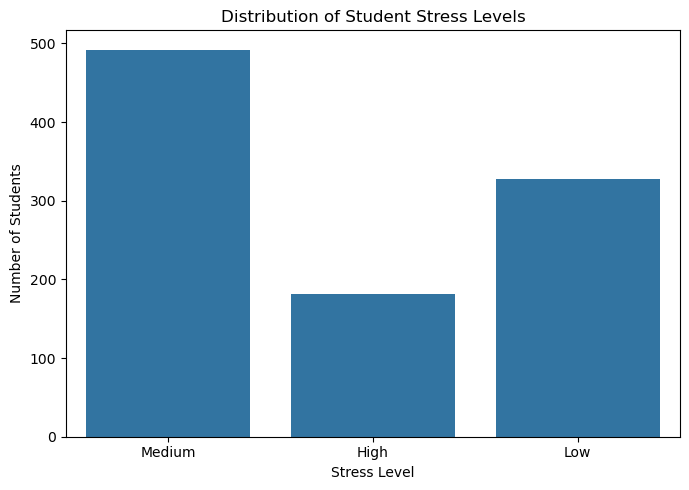

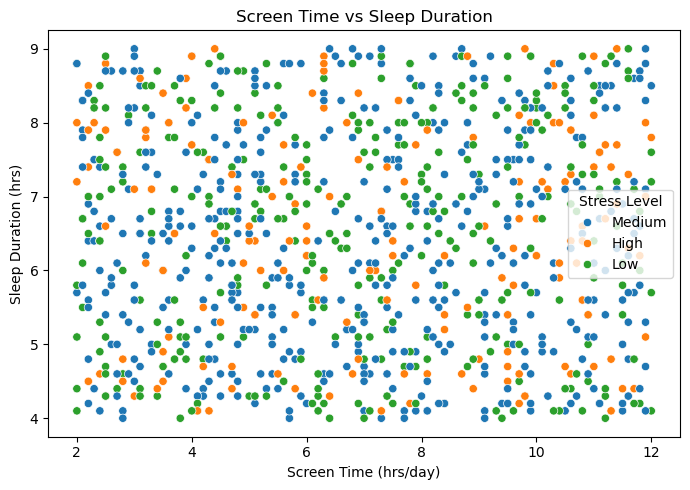

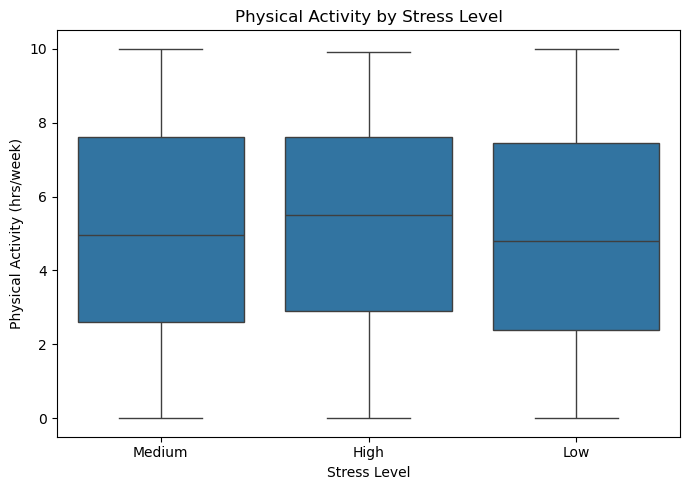

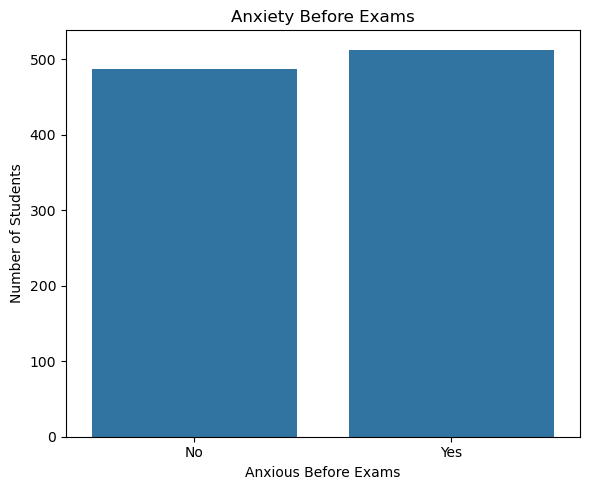

In [6]:
# Graph 1: Distribution of Stress Level
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Stress Level")
plt.title("Distribution of Student Stress Levels")
plt.xlabel("Stress Level")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


# Graph 2: Screen Time vs Sleep Duration
plt.figure(figsize=(7, 5))
sns.scatterplot(
    data=df,
    x="Screen Time (hrs/day)",
    y="Sleep Duration (hrs)",
    hue="Stress Level"
)
plt.title("Screen Time vs Sleep Duration")
plt.tight_layout()
plt.show()


# Graph 3: Physical Activity vs Stress Level
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=df,
    x="Stress Level",
    y="Physical Activity (hrs/week)"
)
plt.title("Physical Activity by Stress Level")
plt.tight_layout()
plt.show()


# Graph 4: Anxiety Before Exams
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="Anxious Before Exams")
plt.title("Anxiety Before Exams")
plt.xlabel("Anxious Before Exams")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

CALCULATE EXACT INSIGHTS

In [7]:
# 1. Exact count and percentage of stress levels
print("STRESS LEVEL DISTRIBUTION")
stress_count = df["Stress Level"].value_counts()
stress_percent = (
    df["Stress Level"].value_counts(normalize=True) * 100
)

stress_summary = pd.DataFrame({
    "Count": stress_count,
    "Percentage": stress_percent.round(2)
})

display(stress_summary)


# 2. Exam anxiety count and percentage
print("EXAM ANXIETY DISTRIBUTION")
anxiety_summary = pd.DataFrame({
    "Count": df["Anxious Before Exams"].value_counts(),
    "Percentage": (
        df["Anxious Before Exams"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

display(anxiety_summary)


# 3. Average lifestyle measurements by stress level
print("AVERAGES BY STRESS LEVEL")
stress_analysis = df.groupby("Stress Level")[
    [
        "Screen Time (hrs/day)",
        "Sleep Duration (hrs)",
        "Physical Activity (hrs/week)"
    ]
].mean().round(2)

display(stress_analysis)


# 4. Academic performance change distribution
print("ACADEMIC PERFORMANCE CHANGE")
display(
    df["Academic Performance Change"]
    .value_counts()
    .to_frame("Count")
)


# 5. Correlation between numerical variables
print("NUMERICAL CORRELATION")
numeric_cols = [
    "Age",
    "Screen Time (hrs/day)",
    "Sleep Duration (hrs)",
    "Physical Activity (hrs/week)"
]

display(df[numeric_cols].corr().round(2))

STRESS LEVEL DISTRIBUTION


,Count,Percentage
Stress Level,,
Medium,492,49.2
Low,327,32.7
High,181,18.1


EXAM ANXIETY DISTRIBUTION


,Count,Percentage
Anxious Before Exams,,
Yes,513,51.3
No,487,48.7


AVERAGES BY STRESS LEVEL


,Screen Time (hrs/day),Sleep Duration (hrs),Physical Activity (hrs/week)
Stress Level,,,
High,7.06,6.47,5.15
Low,6.88,6.51,4.84
Medium,6.87,6.40,5.08


ACADEMIC PERFORMANCE CHANGE


,Count
Academic Performance Change,
Same,399
Improved,303
Declined,298


NUMERICAL CORRELATION


,Age,Screen Time (hrs/day),Sleep Duration (hrs),Physical Activity (hrs/week)
Age,1.00,0.01,-0.01,-0.03
Screen Time (hrs/day),0.01,1.00,0.01,0.03
Sleep Duration (hrs),-0.01,0.01,1.00,-0.01
Physical Activity (hrs/week),-0.03,0.03,-0.01,1.00


RELATIONSHIP ANALYSIS

In [8]:
# Stress level vs exam anxiety
print("Stress Level vs Exam Anxiety")
display(pd.crosstab(
    df["Stress Level"],
    df["Anxious Before Exams"],
    margins=True
))

# Stress level vs academic performance change
print("\nStress Level vs Academic Performance Change")
display(pd.crosstab(
    df["Stress Level"],
    df["Academic Performance Change"],
    margins=True
))

# Average values for all stress groups
print("\nMean lifestyle measurements by stress level")
display(
    df.groupby("Stress Level")[
        [
            "Screen Time (hrs/day)",
            "Sleep Duration (hrs)",
            "Physical Activity (hrs/week)"
        ]
    ].mean().round(2)
)

Stress Level vs Exam Anxiety


Anxious Before Exams,No,Yes,All
Stress Level,,,
High,81,100,181
Low,166,161,327
Medium,240,252,492
All,487,513,1000



Stress Level vs Academic Performance Change


Academic Performance Change,Declined,Improved,Same,All
Stress Level,,,,
High,51,54,76,181
Low,92,104,131,327
Medium,155,145,192,492
All,298,303,399,1000



Mean lifestyle measurements by stress level


,Screen Time (hrs/day),Sleep Duration (hrs),Physical Activity (hrs/week)
Stress Level,,,
High,7.06,6.47,5.15
Low,6.88,6.51,4.84
Medium,6.87,6.40,5.08
